# EDA Data Clean — RM Copilot Corporate/Wholesale

Notebook ini mengulang eksplorasi menggunakan **hasil cleaning** dari `data/processed/clean/` dan membaca seluruh dataset dalam format **Parquet**. Analisis mencakup kualitas hasil cleaning, profil portofolio, peluang pembiayaan, produk wholesale, saldo, transaksi/value chain, dan nasabah perorangan.

**Catatan interpretasi:** dataset bersifat sintetis. Temuan menggambarkan data generator dan aturan bisnis yang disimulasikan, bukan kondisi aktual Bank. Data `kunci_evaluasi`/truth tidak digunakan sebagai fitur atau sumber EDA.


In [15]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True})

CURRENT_DIR = Path.cwd().resolve()
PROJECT_DIR = next(
    (p for p in [CURRENT_DIR, *CURRENT_DIR.parents]
     if (p / "data" / "processed" / "clean").exists()),
    CURRENT_DIR
)
CLEAN_DIR = PROJECT_DIR / "data" / "processed" / "clean"
assert CLEAN_DIR.exists(), (
    f"Folder clean tidak ditemukan: {CLEAN_DIR}. "
    "Jalankan notebook dari root repo atau sesuaikan PROJECT_DIR."
)
print("Project:", PROJECT_DIR)
print("Clean data:", CLEAN_DIR)


Project: value-chain-rm-copilot
Clean data: value-chain-rm-copilot\data\processed\clean


## 1. Memuat seluruh dataset Parquet

Semua file `.parquet` pada folder clean dibaca otomatis. Nama dataset mengikuti nama file tanpa ekstensi, sehingga tidak ada ketergantungan pada file CSV mentah.


In [16]:
parquet_files = sorted(CLEAN_DIR.glob("*.parquet"))
assert parquet_files, f"Tidak ada file Parquet di {CLEAN_DIR}"

data = {p.stem: pd.read_parquet(p) for p in parquet_files}
inventory = pd.DataFrame([
    {"dataset": name, "baris": len(df), "kolom": len(df.columns),
     "ukuran_memori_mb": round(df.memory_usage(deep=True).sum() / 1024**2, 2)}
    for name, df in data.items()
]).sort_values("baris", ascending=False).reset_index(drop=True)

display(inventory)
print(f"Total dataset: {len(data)}")
print("Dataset tersedia:", ", ".join(data.keys()))


,dataset,baris,kolom,ukuran_memori_mb
0,nasabah_bulanan,886639,22,75.15
1,transfers,797611,7,67.00
2,transaksi_counterparty,543452,12,94.64
3,saldo,86683,5,4.71
4,persons,74406,9,9.10
5,nasabah,55928,11,8.84
6,acquisitions,32720,7,2.40
7,employment,30637,5,1.83
8,companies,19994,20,4.08
9,riwayat_produk_wholesale,15223,10,2.32


Total dataset: 15
Dataset tersedia: acquisitions, companies, employment, fasilitas_pembiayaan, label_wholesale, lead_bisdev, nasabah, nasabah_bulanan, persons, produk_level, riwayat_produk_wholesale, rm_portofolio, saldo, transaksi_counterparty, transfers


## 2. Quality check setelah cleaning

Pemeriksaan ini bukan untuk menuntut semua kolom bebas missing. Missing demografi dan atribut entitas non-nasabah dapat bersifat struktural. Fokusnya adalah ukuran dataset, missing value, duplikasi penuh, dan duplikasi pada business key yang relevan.


In [17]:
KEYS = {
    "nasabah": ["person_id"],
    "nasabah_bulanan": ["person_id", "bulan_ke"],
    "companies": ["company_id"],
    "persons": ["person_id"],
    "employment": ["person_id", "company_id", "peran"],
    "transfers": ["bulan_ke", "from_id", "to_id"],
    "saldo": ["company_id", "bulan_ke"],
    "transaksi_counterparty": ["bulan_ke", "company_id", "counterparty_id", "arah"],
    "riwayat_produk_wholesale": ["company_id", "produk", "tanggal_mulai"],
    "fasilitas_pembiayaan": ["company_id", "produk", "tanggal_mulai"],
    "rm_portofolio": ["company_id"],
    "lead_bisdev": ["lead_id"],
    "acquisitions": ["entity_id"],
}
quality_rows, missing_rows = [], []
for name, df in data.items():
    key_cols = KEYS.get(name, [])
    existing_keys = [c for c in key_cols if c in df.columns]
    quality_rows.append({
        "dataset": name,
        "baris": len(df),
        "kolom": len(df.columns),
        "duplikat_baris_penuh": int(df.duplicated().sum()),
        "kolom_key_tersedia": ", ".join(existing_keys),
        "duplikat_business_key": int(df.duplicated(existing_keys).sum()) if existing_keys else np.nan,
        "missing_total": int(df.isna().sum().sum()),
        "missing_pct_sel": round(df.isna().sum().sum() / max(df.size, 1) * 100, 3),
    })
    miss = df.isna().sum()
    for col, n in miss[miss.gt(0)].items():
        missing_rows.append({
            "dataset": name, "kolom": col, "missing": int(n),
            "missing_pct_baris": round(n / max(len(df), 1) * 100, 2)
        })
quality = pd.DataFrame(quality_rows).sort_values("missing_pct_sel", ascending=False)
missing_detail = pd.DataFrame(missing_rows)
display(quality)
if not missing_detail.empty:
    display(missing_detail.sort_values(["missing_pct_baris", "missing"], ascending=False).head(50))
else:
    print("Tidak ditemukan missing value.")


,dataset,baris,kolom,duplikat_baris_penuh,kolom_key_tersedia,duplikat_business_key,missing_total,missing_pct_sel
0,acquisitions,32720,7,0,entity_id,0.0,90067,39.324
1,companies,19994,20,0,company_id,0.0,153416,38.366
10,riwayat_produk_wholesale,15223,10,0,"company_id, produk, tanggal_mulai",0.0,40650,26.703
5,lead_bisdev,1500,8,0,lead_id,0.0,3008,25.067
8,persons,74406,9,0,person_id,0.0,110868,16.556
6,nasabah,55928,11,0,person_id,0.0,60752,9.875
4,label_wholesale,2081,6,0,,NaN,237,1.898
3,fasilitas_pembiayaan,2942,7,0,"company_id, produk, tanggal_mulai",0.0,0,0.000
2,employment,30637,5,0,"person_id, company_id, peran",0.0,0,0.000
7,nasabah_bulanan,886639,22,0,"person_id, bulan_ke",0.0,1,0.000


,dataset,kolom,missing,missing_pct_baris
22,nasabah,bulan_keluar,54432,97.33
2,acquisitions,via_anchor_id,31665,96.78
12,companies,rm_id,18761,93.83
32,riwayat_produk_wholesale,tanggal_selesai,13884,91.20
0,acquisitions,tanggal_jadi_nasabah,29201,89.25
1,acquisitions,produk_pertama,29201,89.25
33,riwayat_produk_wholesale,beneficiary_id,13383,87.91
34,riwayat_produk_wholesale,nilai_proyek_rp,13383,87.91
3,companies,skala,14895,74.50
4,companies,peran,14895,74.50


### Cara membaca hasil quality check

- **Missing tidak otomatis error.** Missing pada profil non-nasabah dapat mencerminkan batas informasi yang terlihat bank.
- **Duplikasi business key perlu ditinjau**, terutama pada panel bulanan, saldo, transfer, dan transaksi counterpart. Key pada tabel di atas adalah pemeriksaan awal; sesuaikan bila grain resmi dataset berbeda.
- `data_quality_report.csv` dari pipeline cleaning tetap menjadi referensi validasi pipeline; tabel di notebook ini adalah pemeriksaan independen terhadap file output.


## 3. Menyiapkan populasi analisis corporate/wholesale

Analisis portofolio difokuskan pada perusahaan nasabah Bank dengan segmen `Commercial` atau `Corporate`. Kode menggunakan kolom yang tersedia pada hasil cleaning dan berhenti dengan pesan jelas jika kolom inti tidak ditemukan.


In [18]:
companies = data["companies"].copy()
required = ["company_id", "is_bank_customer", "segmen_bank"]
missing_required = [c for c in required if c not in companies.columns]
assert not missing_required, f"Kolom inti companies tidak ditemukan: {missing_required}"

companies["is_bank_customer"] = pd.to_numeric(companies["is_bank_customer"], errors="coerce")
corporate = companies[
    companies["is_bank_customer"].eq(1)
    & companies["segmen_bank"].isin(["Commercial", "Corporate"])
].copy()

if "omzet_tahunan_rp" in corporate:
    corporate["omzet_miliar"] = pd.to_numeric(corporate["omzet_tahunan_rp"], errors="coerce") / 1e9
if "tahun_berdiri" in corporate:
    corporate["umur_usaha"] = 2025 - pd.to_numeric(corporate["tahun_berdiri"], errors="coerce")
if "is_anchor" in corporate:
    corporate["is_anchor"] = corporate["is_anchor"].astype("boolean")

print(f"Perusahaan terlihat bank: {len(companies):,}")
print(f"Nasabah Bank segmen Commercial/Corporate: {corporate['company_id'].nunique():,}")
display(corporate.head())


Perusahaan terlihat bank: 19,994
Nasabah Bank segmen Commercial/Corporate: 1,233


,company_id,is_anchor,sektor,provinsi,skala,peran,nama_samaran,omzet_tahunan_rp,jumlah_karyawan,tahun_berdiri,bank_utama,bank_payroll,is_bank_customer,produk_bank,segmen_bank,cif,status_debitur_awal,ada_pic_terdaftar,rm_id,cabang,omzet_miliar,umur_usaha
0,C000000,True,F,Aceh,Besar,ANCHOR,PT Anchor 0000,1.845500e+11,237.0,NaN,Bank,BANK_B,1,Bank Giro (Non Perorangan);CIB;CIB ...,Corporate,CIF9000000,0,1,RM019,KC Jawa Barat,184.550,NaN
1,C000001,True,"R,S,T,U",Aceh,Menengah,ANCHOR,PT Anchor 0001,4.028800e+10,72.0,2001.0,Bank,Bank,1,Bank Giro (Non Perorangan);CIB;CIB ...,Commercial,CIF9000001,1,1,RM000,KC Aceh,40.288,24.0
2,C000002,True,G,Lampung,Besar,ANCHOR,PT Anchor 0002,3.917900e+11,205.0,1994.0,Bank,BANK_A,1,Bank Giro (Non Perorangan);CIB;CIB ...,Corporate,CIF9000002,1,1,RM021,KC Nusa Tenggara Timur,391.790,31.0
3,C000003,True,F,Jawa Timur,Menengah,ANCHOR,PT Anchor 0003,4.610200e+10,62.0,2002.0,Bank,Bank,1,Bank Giro (Non Perorangan);CIB;CIB ...,Commercial,CIF9000003,0,1,RM008,KC Jawa Tengah,46.102,23.0
4,C000004,True,C,Jawa Tengah,Besar,ANCHOR,PT Anchor 0004,1.013830e+11,665.0,2022.0,Bank,Bank,1,Bank Giro (Non Perorangan);CIB;CIB ...,Commercial,CIF9000004,1,1,RM007,KC Jawa Tengah,101.383,3.0


## 4. Profil portofolio: segmen, sektor, wilayah, dan skala

Selain jumlah perusahaan, median omzet dan ukuran perusahaan membantu membedakan **peluang berdasarkan volume** dari **peluang berdasarkan skala**. Median dipilih karena lebih tahan terhadap nilai ekstrem dibanding rata-rata.


,perusahaan,median_omzet_miliar,median_karyawan,porsi_debitur,porsi_anchor
segmen_bank,,,,,
Commercial,1026,22.886,47.0,0.667,0.021
Corporate,207,571.071,157.0,0.725,0.135


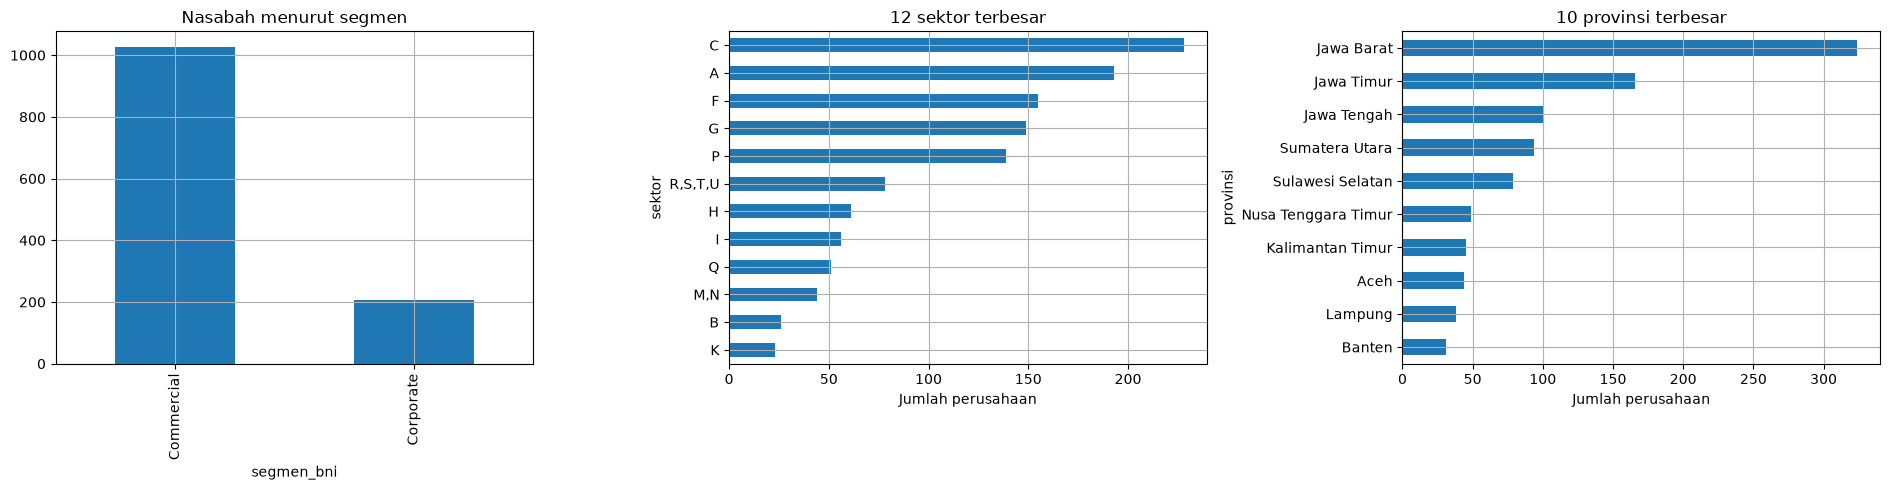

,perusahaan,porsi_debitur
sektor,,
C,228,0.711
A,193,0.632
F,155,0.677
G,149,0.691
P,139,0.676
"R,S,T,U",78,0.641
H,61,0.639
I,56,0.696
Q,51,0.706


In [19]:
def first_existing(df, candidates):
    return next((c for c in candidates if c in df.columns), None)

sector_col = first_existing(corporate, ["sektor_nama", "sektor"])
region_col = first_existing(corporate, ["provinsi"])
debt_col = first_existing(corporate, ["status_debitur_awal", "status_debitur"])
anchor_col = first_existing(corporate, ["is_anchor"])

agg = {"perusahaan": ("company_id", "nunique")}
if "omzet_miliar" in corporate: agg["median_omzet_miliar"] = ("omzet_miliar", "median")
if "jumlah_karyawan" in corporate: agg["median_karyawan"] = ("jumlah_karyawan", "median")
if debt_col: agg["porsi_debitur"] = (debt_col, "mean")
if anchor_col: agg["porsi_anchor"] = (anchor_col, "mean")
segment_summary = corporate.groupby("segmen_bank", dropna=False).agg(**agg).sort_values("perusahaan", ascending=False)
display(segment_summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
corporate["segmen_bank"].value_counts().plot.bar(ax=axes[0], title="Nasabah menurut segmen")
if sector_col:
    corporate[sector_col].value_counts().head(12).sort_values().plot.barh(ax=axes[1], title="12 sektor terbesar")
    axes[1].set_xlabel("Jumlah perusahaan")
if region_col:
    corporate[region_col].value_counts().head(10).sort_values().plot.barh(ax=axes[2], title="10 provinsi terbesar")
    axes[2].set_xlabel("Jumlah perusahaan")
plt.tight_layout(); plt.show()

if sector_col and debt_col:
    sector_debt = corporate.groupby(sector_col).agg(
        perusahaan=("company_id", "nunique"),
        porsi_debitur=(debt_col, "mean")
    ).sort_values("perusahaan", ascending=False)
    display(sector_debt.head(15).round(3))


### Insight lebih mendalam: ukuran dan konsentrasi portofolio

Bandingkan sektor/wilayah dengan jumlah perusahaan tinggi dan proporsi debitur rendah. Kelompok seperti ini dapat menjadi **daftar eksplorasi coverage**, bukan otomatis prospek layak pembiayaan. Pertimbangkan juga omzet, fasilitas berjalan, riwayat produk, saldo, dan transaksi.


,metrik,nilai,nilai_pct
0,Porsi 3 sektor terbesar,0.467153,46.72
1,Porsi 5 sektor terbesar,0.700730,70.07


Median omzet (Rp miliar): 27.3
P90 omzet (Rp miliar): 426.33
Porsi perusahaan dengan omzet di atas P90: 10.06 %


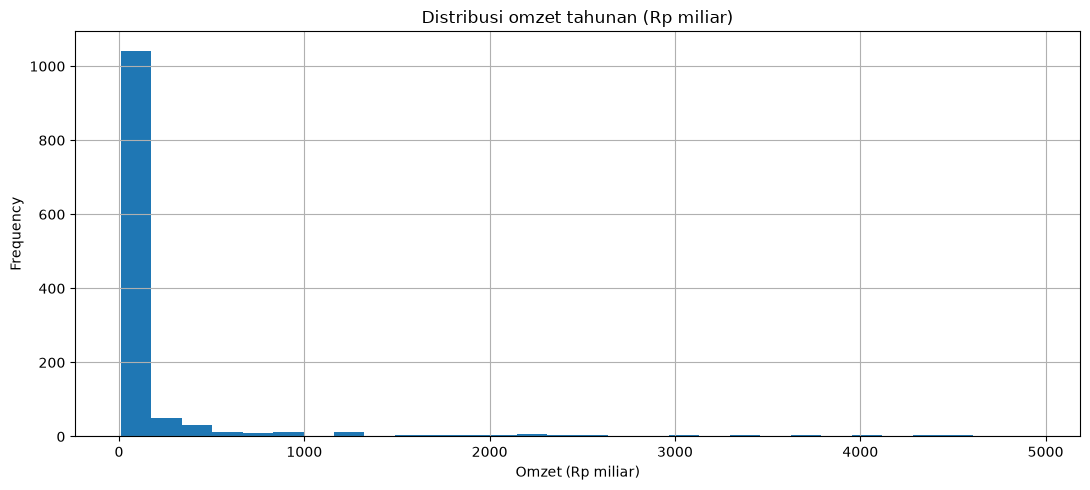

In [20]:
# Konsentrasi sektor: berapa porsi portofolio berada pada 3/5 sektor terbesar?
if sector_col:
    sector_counts = corporate[sector_col].value_counts(dropna=False)
    total = sector_counts.sum()
    concentration = pd.DataFrame({
        "metrik": ["Porsi 3 sektor terbesar", "Porsi 5 sektor terbesar"],
        "nilai": [sector_counts.head(3).sum()/total, sector_counts.head(5).sum()/total]
    })
    display(concentration.assign(nilai_pct=(concentration["nilai"]*100).round(2)))

# Periksa apakah omzet terkonsentrasi pada sebagian kecil perusahaan
if "omzet_miliar" in corporate:
    omzet = corporate.loc[corporate["omzet_miliar"].gt(0), "omzet_miliar"].dropna()
    if len(omzet):
        print("Median omzet (Rp miliar):", round(omzet.median(), 2))
        print("P90 omzet (Rp miliar):", round(omzet.quantile(.90), 2))
        print("Porsi perusahaan dengan omzet di atas P90:", round((omzet > omzet.quantile(.90)).mean()*100, 2), "%")
        omzet.plot.hist(bins=30, title="Distribusi omzet tahunan (Rp miliar)")
        plt.xlabel("Omzet (Rp miliar)"); plt.tight_layout(); plt.show()


## 5. Coverage RM dan peluang non-debitur

Tabel ini mengidentifikasi sebaran portofolio dan variasi porsi non-debitur antar-RM. Gunakan rasio dan jumlah absolut secara bersamaan: RM dengan porsi tinggi tetapi portofolio kecil belum tentu memiliki jumlah prospek terbesar.


,perusahaan,debitur,omzet_median_miliar,non_debitur,porsi_non_debitur
rm_id,,,,,
RM017,55,27,21.625,28,0.509
RM006,55,31,23.198,24,0.436
RM014,55,32,21.250,23,0.418
RM007,55,34,24.117,21,0.382
RM008,55,34,22.433,21,0.382
RM000,55,34,30.095,21,0.382
RM004,55,36,22.758,19,0.345
RM013,55,36,23.855,19,0.345
RM010,55,36,21.606,19,0.345


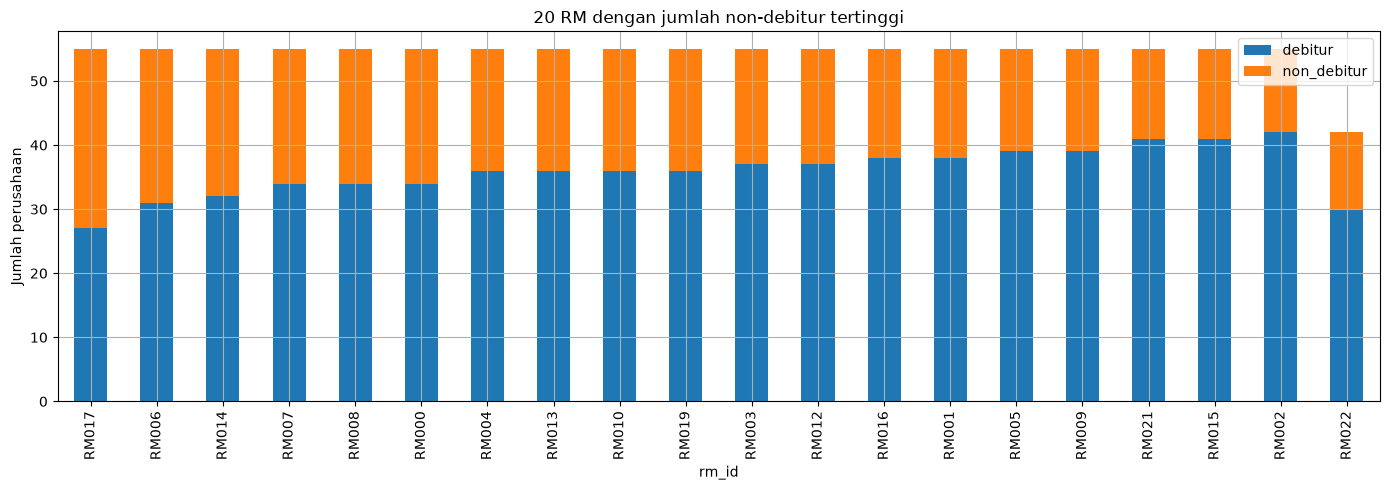

In [21]:
rm_summary = pd.DataFrame()
if "rm_portofolio" in data:
    rm = data["rm_portofolio"].copy()
    join_cols = ["company_id"] + [c for c in [sector_col, region_col, "omzet_tahunan_rp", anchor_col] if c and c in corporate.columns]
    rm = rm.merge(corporate[join_cols].drop_duplicates("company_id"), on="company_id", how="left", suffixes=("", "_company"))
    if "omzet_tahunan_rp" in rm:
        rm["omzet_miliar"] = pd.to_numeric(rm["omzet_tahunan_rp"], errors="coerce") / 1e9
    if debt_col and debt_col in rm:
        rm["debitur_flag"] = pd.to_numeric(rm[debt_col], errors="coerce")
    elif "status_debitur_awal" in rm:
        rm["debitur_flag"] = pd.to_numeric(rm["status_debitur_awal"], errors="coerce")
    else:
        rm["debitur_flag"] = np.nan
    rm_summary = rm.groupby("rm_id", dropna=False).agg(
        perusahaan=("company_id", "nunique"),
        debitur=("debitur_flag", "sum"),
        omzet_median_miliar=("omzet_miliar", "median") if "omzet_miliar" in rm else ("company_id", "count")
    )
    rm_summary["non_debitur"] = rm_summary["perusahaan"] - rm_summary["debitur"]
    rm_summary["porsi_non_debitur"] = rm_summary["non_debitur"] / rm_summary["perusahaan"]
    display(rm_summary.sort_values("non_debitur", ascending=False).round(3))
    rm_summary.sort_values("non_debitur", ascending=False).head(20)[["debitur","non_debitur"]].plot.bar(
        stacked=True, figsize=(14,5), title="20 RM dengan jumlah non-debitur tertinggi"
    )
    plt.ylabel("Jumlah perusahaan"); plt.tight_layout(); plt.show()
else:
    print("Dataset rm_portofolio tidak tersedia.")


## 6. Fasilitas pembiayaan dan ruang coverage

Bedakan perusahaan yang belum tercatat memiliki fasilitas dengan perusahaan yang tidak layak memperoleh pembiayaan. EDA hanya menunjukkan coverage dalam data, bukan keputusan kredit.


In [22]:
if "fasilitas_pembiayaan" in data:
    fac = data["fasilitas_pembiayaan"].copy()
    fac["plafon_rp"] = pd.to_numeric(fac.get("plafon_rp"), errors="coerce")
    fac["baki_debet_rp"] = pd.to_numeric(fac.get("baki_debet_rp"), errors="coerce")
    display(fac.groupby("produk", dropna=False).agg(
        jumlah_fasilitas=("company_id", "size"),
        perusahaan=("company_id", "nunique"),
        plafon_miliar=("plafon_rp", lambda x: x.sum()/1e9),
        baki_debet_miliar=("baki_debet_rp", lambda x: x.sum()/1e9)
    ).sort_values("baki_debet_miliar", ascending=False).round(2))

    facility_ids = set(fac["company_id"].dropna())
    coverage = corporate.groupby("segmen_bank").agg(perusahaan=("company_id","nunique"))
    coverage["punya_fasilitas"] = corporate.groupby("segmen_bank")["company_id"].apply(lambda s: s.isin(facility_ids).sum())
    coverage["tanpa_fasilitas_tercatat"] = coverage["perusahaan"] - coverage["punya_fasilitas"]
    coverage["porsi_tanpa_fasilitas"] = coverage["tanpa_fasilitas_tercatat"] / coverage["perusahaan"]
    display(coverage.round(3))
else:
    print("Dataset fasilitas_pembiayaan tidak tersedia.")


,jumlah_fasilitas,perusahaan,plafon_miliar,baki_debet_miliar
produk,,,,
Kredit Modal Kerja,1428,1428,52866.30,35770.75
Kredit Investasi,532,532,26966.21,17923.61
Supply Chain Financing,302,302,6068.81,3723.31
KUR Kecil,236,236,48.83,30.52
KUR Mikro,444,444,19.10,11.73


,perusahaan,punya_fasilitas,tanpa_fasilitas_tercatat,porsi_tanpa_fasilitas
segmen_bank,,,,
Commercial,1026,797,229,0.223
Corporate,207,183,24,0.116


## 7. Produk wholesale: status aktif, reaktivasi, dan nilai proyek

Peluang reaktivasi perlu dihitung dari jumlah perusahaan unik per produk, bukan hanya jumlah baris riwayat. Perusahaan dapat memiliki lebih dari satu catatan produk.


,produk,status,perusahaan,catatan
22,Payroll Korporasi,AKTIF,990,990
10,CIB,AKTIF,940,940
4,Bank Giro (Non Perorangan),AKTIF,940,940
2,Bank Deposito Non Perorangan,AKTIF,559,559
19,Garansi Bank,TIDAK AKTIF,298,315
5,Tabungan Plus Bisnis,AKTIF,293,293
8,Bank Virtual Account Kredit (e-Collection),AKTIF,202,202
18,Garansi Bank,AKTIF,189,189
6,Bank Virtual Account Debit,AKTIF,183,183
26,SKBDN,TIDAK AKTIF,100,102


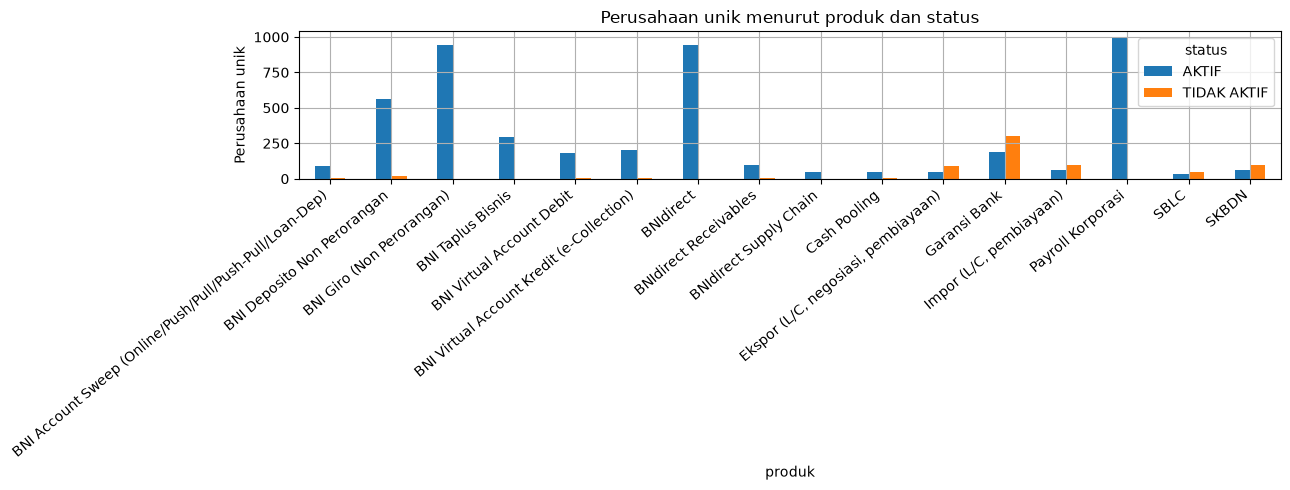

,perusahaan_kandidat,catatan
produk,,
Garansi Bank,298,315
SKBDN,100,102
"Impor (L/C, pembiayaan)",94,95
"Ekspor (L/C, negosiasi, pembiayaan)",88,89
SBLC,47,48
Bank Deposito Non Perorangan,17,17
Bank Virtual Account Debit,6,6
Bank Account Sweep (Online/Push/Pull/Push-Pull/Loan-Dep),4,4
Bank Virtual Account Kredit (e-Collection),3,3


,count,median,sum
produk,,,
Garansi Bank,504,4.909000e+09,2.221388e+13
SKBDN,166,5.390000e+09,8.879256e+12
SBLC,83,1.186300e+10,8.508723e+12
"Impor (L/C, pembiayaan)",158,4.871500e+09,6.902044e+12
"Ekspor (L/C, negosiasi, pembiayaan)",139,5.397000e+09,6.816038e+12
Bank Account Sweep (Online/Push/Pull/Push-Pull/Loan-Dep),0,NaN,0.000000e+00
Bank Giro (Non Perorangan),0,NaN,0.000000e+00
Bank Deposito Non Perorangan,0,NaN,0.000000e+00
CIB Receivables,0,NaN,0.000000e+00


In [23]:
if "riwayat_produk_wholesale" in data:
    history = data["riwayat_produk_wholesale"].merge(
        corporate[["company_id","segmen_bank"] + ([sector_col] if sector_col else [])],
        on="company_id", how="inner"
    )
    status_col = first_existing(history, ["status", "status_produk"])
    product_col = first_existing(history, ["produk", "nama_produk"])
    value_col = first_existing(history, ["nilai_proyek_rp", "nilai_proyek"])
    if product_col and status_col:
        product_status = history.groupby([product_col, status_col]).agg(
            perusahaan=("company_id","nunique"), catatan=(product_col,"size")
        ).reset_index()
        display(product_status.sort_values("perusahaan", ascending=False))
        pivot = history.pivot_table(index=product_col, columns=status_col, values="company_id",
                                    aggfunc="nunique", fill_value=0)
        pivot.plot.bar(figsize=(13,5), title="Perusahaan unik menurut produk dan status")
        plt.ylabel("Perusahaan unik"); plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()
        inactive_labels = {"TIDAK AKTIF", "TIDAK_AKTIF", "INACTIVE", "NONAKTIF"}
        inactive_rows = history[history[status_col].astype(str).str.upper().isin(inactive_labels)]
        inactive_summary = inactive_rows.groupby(product_col).agg(
            perusahaan_kandidat=("company_id","nunique"), catatan=("company_id","size")
        ).sort_values("perusahaan_kandidat", ascending=False)
        display(inactive_summary)
    if value_col and product_col:
        history[value_col] = pd.to_numeric(history[value_col], errors="coerce")
        display(history.groupby(product_col)[value_col].agg(["count","median","sum"]).sort_values("sum", ascending=False).round(2))
else:
    print("Dataset riwayat_produk_wholesale tidak tersedia.")


## 8. Tren saldo: level, perubahan, dan volatilitas

Selain total saldo, analisis median per perusahaan, perubahan bulan-ke-bulan, dan volatilitas membantu membedakan pertumbuhan agregat dari perubahan yang hanya dipengaruhi beberapa perusahaan besar. Nilai ekstrem tetap perlu ditafsirkan dengan hati-hati walaupun sudah melalui cleaning.


,bulan_ke,segmen_bank,total_saldo_miliar,median_saldo_miliar,perusahaan
0,1,Commercial,1346.301,0.993,1026
1,1,Corporate,12717.776,29.979,207
2,2,Commercial,1351.790,1.014,1026
3,2,Corporate,12565.936,27.506,207
4,3,Commercial,1338.091,0.997,1026
5,3,Corporate,12726.628,28.466,207
6,4,Commercial,1344.927,1.006,1026
7,4,Corporate,12595.276,27.491,207
8,5,Commercial,1349.149,1.006,1026
9,5,Corporate,12741.967,26.554,207


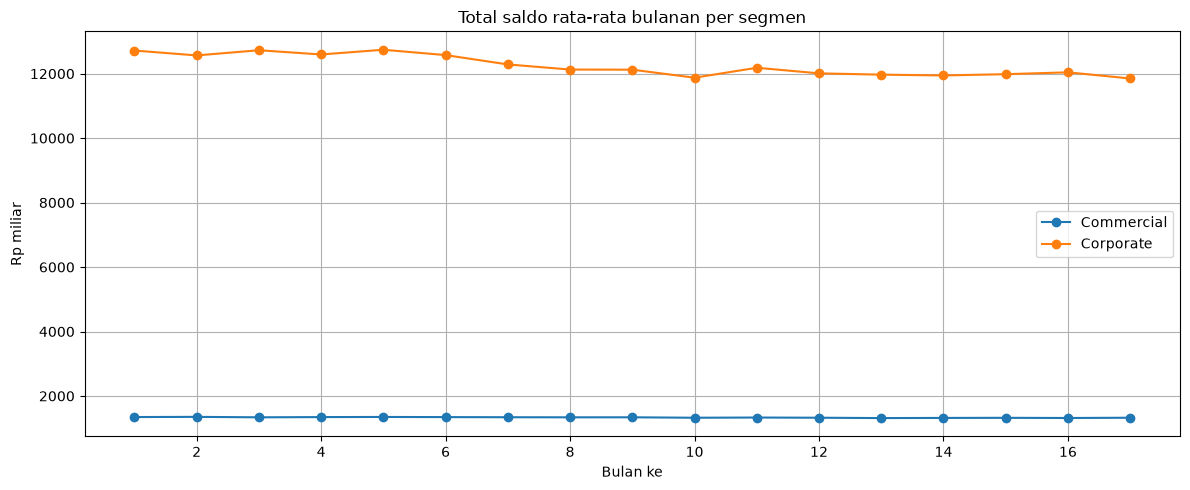

,total_saldo_miliar,perubahan_mom_pct
bulan_ke,,
1,14064.08,NaN
2,13917.73,-1.04
3,14064.72,1.06
4,13940.20,-0.89
5,14091.12,1.08
6,13920.64,-1.21
7,13627.00,-2.11
8,13465.57,-1.18
9,13461.43,-0.03


Bulan dengan perubahan absolut terbesar: 11 | perubahan: 2.38 %


In [24]:
if "saldo" in data:
    saldo = data["saldo"].copy()
    saldo_col = first_existing(saldo, ["saldo_rata2_rp"])
    if saldo_col and {"company_id","bulan_ke"}.issubset(saldo.columns):
        saldo[saldo_col] = pd.to_numeric(saldo[saldo_col], errors="coerce")
        saldo["saldo_miliar"] = saldo[saldo_col] / 1e9
        saldo = saldo.merge(corporate[["company_id","segmen_bank"]], on="company_id", how="inner")
        monthly = saldo.groupby(["bulan_ke","segmen_bank"]).agg(
            total_saldo_miliar=("saldo_miliar","sum"),
            median_saldo_miliar=("saldo_miliar","median"),
            perusahaan=("company_id","nunique")
        ).reset_index()
        display(monthly.head(20).round(3))
        fig, ax = plt.subplots(figsize=(12,5))
        for seg, g in monthly.groupby("segmen_bank"):
            ax.plot(g["bulan_ke"], g["total_saldo_miliar"], marker="o", label=seg)
        ax.set_title("Total saldo rata-rata bulanan per segmen")
        ax.set_xlabel("Bulan ke"); ax.set_ylabel("Rp miliar"); ax.legend()
        plt.tight_layout(); plt.show()

        # Perubahan MoM pada total saldo untuk mengidentifikasi lonjakan
        total_month = saldo.groupby("bulan_ke")["saldo_miliar"].sum().sort_index()
        mom = total_month.pct_change()*100
        display(pd.DataFrame({"total_saldo_miliar": total_month, "perubahan_mom_pct": mom}).round(2))
        print("Bulan dengan perubahan absolut terbesar:", mom.abs().idxmax(), "| perubahan:", round(mom.loc[mom.abs().idxmax()], 2), "%")


## 9. Transaksi counterparty: konsentrasi, bank lain, dan sinyal value chain

Analisis dibedakan antara **porsi baris transaksi** dan **porsi nominal** ke bank lain. Porsi baris tidak sama dengan porsi nilai uang. Identitas counterpart dan sinyal perpindahan bank harus ditangani sesuai kebijakan privasi, tujuan penggunaan, dan persetujuan yang berlaku.


In [25]:
if "transaksi_counterparty" in data:
    tx = data["transaksi_counterparty"].merge(
        corporate[["company_id","segmen_bank"]], on="company_id", how="inner"
    ).copy()
    tx["total_nominal_rp"] = pd.to_numeric(tx.get("total_nominal_rp"), errors="coerce")
    bank_col = first_existing(tx, ["counterparty_bank", "bank_counterparty"])
    direction_col = first_existing(tx, ["arah"])
    if bank_col:
        tx["bank_lain_flag"] = ~tx[bank_col].astype(str).str.strip().str.upper().eq("Bank")
    group_cols = ["segmen_bank"] + ([direction_col] if direction_col else [])
    metrics = {
        "baris_transaksi": ("company_id","size"),
        "perusahaan": ("company_id","nunique"),
        "counterpart_unik": ("counterparty_id","nunique") if "counterparty_id" in tx else ("company_id","nunique"),
        "nominal_miliar": ("total_nominal_rp", lambda x: x.sum()/1e9)
    }
    if "jumlah_transaksi" in tx:
        tx["jumlah_transaksi"] = pd.to_numeric(tx["jumlah_transaksi"], errors="coerce")
        metrics["jumlah_transaksi"] = ("jumlah_transaksi","sum")
    if "bank_lain_flag" in tx:
        metrics["porsi_baris_bank_lain"] = ("bank_lain_flag","mean")
        tx["nominal_bank_lain_rp"] = tx["total_nominal_rp"].where(tx["bank_lain_flag"], 0)
        metrics["nominal_bank_lain_miliar"] = ("nominal_bank_lain_rp", lambda x: x.sum()/1e9)
    display(tx.groupby(group_cols, dropna=False).agg(**metrics).round(3))

    if "counterparty_id" in tx:
        cp_cols = ["company_id","counterparty_id"]
        if bank_col: cp_cols += [bank_col]
        if "counterparty_nama" in tx: cp_cols += ["counterparty_nama"]
        top_cp = tx.groupby(cp_cols, dropna=False).agg(
            nominal_miliar=("total_nominal_rp", lambda x: x.sum()/1e9),
            bulan_aktif=("bulan_ke","nunique") if "bulan_ke" in tx else ("company_id","size"),
            baris=("company_id","size")
        ).reset_index().sort_values("nominal_miliar", ascending=False)
        display(top_cp.head(20))
        # Konsentrasi nominal pada 10 relasi perusahaan-counterpart terbesar
        total_nominal = tx["total_nominal_rp"].sum()
        top10_nominal = top_cp.head(10)["nominal_miliar"].sum()*1e9
        print("Porsi nominal pada 10 relasi teratas:", round(top10_nominal/total_nominal*100, 2) if total_nominal else np.nan, "%")
else:
    print("Dataset transaksi_counterparty tidak tersedia.")


baris_transaksi  perusahaan  counterpart_unik  nominal_miliar  jumlah_transaksi  porsi_baris_bank_lain  nominal_bank_lain_miliar
segmen_bank arah                                                                                                                                    
Commercial KELUAR           139671         878              9865       10526.178            476713                  0.715                  6641.653
           MASUK             85442         934              4778        6611.276            455341                  0.649                  3327.457
Corporate  KELUAR            86224         180              6821       40947.410            286767                  0.737                 27253.019
           MASUK             43990         192              2918       19374.886            253295                  0.711                 10008.016

,company_id,counterparty_id,counterparty_bank,counterparty_nama,nominal_miliar,bulan_aktif,baris
67528,C005881,C005881,BANK_C,PT Mitra 5881,1244.004204,16,26
65268,C001190,C001190,BANK_C,PT Mitra 1190,1104.369613,16,25
67176,C005156,C005156,Bank,PT Mitra 5156,1037.817616,17,32
69126,C009471,C009471,BANK_A,PT Mitra 9471,929.571991,16,27
67139,C005071,C005071,Bank,PT Mitra 5071,687.693250,17,31
65589,C001961,C001961,BANK_B,PT Mitra 1961,656.721154,17,31
71628,C014874,C014874,Bank,PT Mitra 14874,651.028713,17,31
68924,C008979,C008979,Bank,PT Mitra 8979,634.768881,16,29
66347,C003397,C003397,Bank,PT Mitra 3397,619.873046,17,33
73684,C019193,C019193,BANK_C,PT Mitra 19193,597.624584,17,28


Porsi nominal pada 10 relasi teratas: 10.54 %


In [30]:
counterparty = pd.read_parquet(
    CLEAN_DIR / "transaksi_counterparty.parquet"
)

In [32]:
for col in ["bank", "kelas_nama_bank", "arah"]:
    if col in counterparty.columns:
        print(f"\nKategori {col}:")
        print(counterparty[col].value_counts(dropna=False))


Kategori kelas_nama_bank:
kelas_nama_bank
NAMA_BEDA_BANK_BEDA    264772
NAMA_BEDA_BANK_SAMA    165426
NAMA_SAMA_BANK_BEDA     73883
NAMA_SAMA_BANK_SAMA     39371
Name: count, dtype: int64

Kategori arah:
arah
KELUAR    308602
MASUK     234850
Name: count, dtype: int64


## 10. Ekosistem anchor dan peluang akuisisi

Anchor dapat menjadi titik awal untuk memahami jaringan supplier/distributor. Insight yang berguna bukan hanya total transaksi, tetapi jumlah counterpart unik, konsistensi aktivitas lintas bulan, dan konsentrasi nominal. Hasil ini merupakan kandidat untuk ditinjau RM, bukan instruksi otomatis untuk menghubungi counterpart.


,counterpart_unik,nominal_miliar,bulan_aktif,porsi_baris_bank_lain
company_id,,,,
C000049,5907,4672.119,17,0.746
C000024,598,3026.066,17,0.733
C000005,393,2800.809,17,0.717
C000037,1154,2737.957,17,0.747
C000015,434,1896.755,17,0.779
C000018,2116,1787.376,17,0.752
C000014,1070,1757.747,17,0.747
C000011,669,1713.373,17,0.721
C000016,210,1399.712,17,0.764


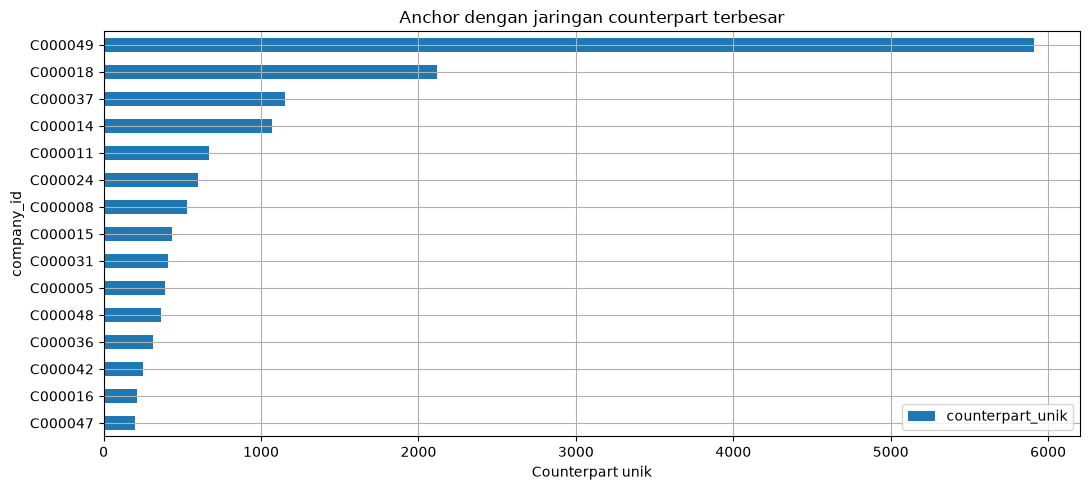

In [26]:
if anchor_col and "counterparty_id" in tx.columns:
    anchor_ids = set(corporate.loc[corporate[anchor_col].fillna(False).astype(bool), "company_id"])
    anchor_tx = tx[tx["company_id"].isin(anchor_ids)].copy()
    if not anchor_tx.empty:
        anchor_metrics = {
            "counterpart_unik": ("counterparty_id","nunique"),
            "nominal_miliar": ("total_nominal_rp", lambda x: x.sum()/1e9),
            "bulan_aktif": ("bulan_ke","nunique") if "bulan_ke" in anchor_tx else ("company_id","size"),
        }
        if "bank_lain_flag" in anchor_tx:
            anchor_metrics["porsi_baris_bank_lain"] = ("bank_lain_flag","mean")
        anchor_summary = anchor_tx.groupby("company_id").agg(**anchor_metrics).sort_values("nominal_miliar", ascending=False)
        display(anchor_summary.head(20).round(3))
        anchor_summary.head(15).sort_values("counterpart_unik").plot.barh(
            y="counterpart_unik", figsize=(11,5), title="Anchor dengan jaringan counterpart terbesar"
        )
        plt.xlabel("Counterpart unik"); plt.tight_layout(); plt.show()
    else:
        print("Belum ada transaksi yang cocok dengan perusahaan anchor pada populasi terpilih.")
else:
    print("Kolom anchor atau counterpart tidak tersedia; bagian ini dilewati.")


## 11. Nasabah perorangan dan penetrasi produk ritel

Nasabah dan panel bulanan dibaca dari Parquet. Analisis menilai profil demografi yang tersedia, channel akuisisi, penetrasi produk terbaru, serta perubahan penetrasi dari waktu ke waktu. Kategori yang missing tetap ditampilkan sebagai `Tidak diketahui` hanya untuk ringkasan visual, tanpa mengubah nilai asli pada data.


Nasabah perorangan: 55,928


,person_id,usia_bulan1,jenis_kelamin,provinsi,perkotaan,pekerjaan,bulan_masuk,bulan_keluar,lama_nasabah_bulan_saat_masuk_panel,channel,kisaran_pendapatan
0,P0141382,63.0,Perempuan,Sulawesi Tenggara,1,Ibu Rumah Tangga,1,NaN,167,Kantor Cabang,Tidak ada penghasilan sendiri
1,P0129292,16.0,Laki-Laki,Jawa Timur,1,Pekerjaan Lainnya,1,NaN,12,Kantor Cabang,"500 rb - 1,5 jt"
2,P0159740,35.0,Laki-Laki,Kalimantan Timur,1,Petani/Peternak/Pekebun/Nelayan,1,NaN,37,Kantor Cabang,"1,5 - 2,5 jt"
3,P0073297,43.0,Laki-Laki,Jawa Timur,1,Pekerjaan Lainnya,1,NaN,12,Kantor Cabang,"2,5 - 3,5 jt"
4,P0103937,45.0,Laki-Laki,Sumatera Utara,1,Pegawai/Profesional,1,NaN,5,Kantor Cabang,"> 3,5 jt"


,Distribusi pekerjaan
pekerjaan,
Pegawai/Profesional,11934
Ibu Rumah Tangga,10330
Petani/Peternak/Pekebun/Nelayan,8507
Pengusaha/Wiraswasta,7737
Pekerjaan Lainnya,6612
Pelajar/Mahasiswa,5422
Tidak/Belum Pernah Bekerja,3077
Tidak diketahui,1678
Pensiunan/Purnawirawan,631


,Distribusi kisaran_pendapatan
kisaran_pendapatan,
Tidak ada penghasilan sendiri,18440
"500 rb - 1,5 jt",10713
"1,5 - 2,5 jt",8738
"> 3,5 jt",6816
"2,5 - 3,5 jt",5544
< 500 rb,2881
Tidak diketahui,2796


,Distribusi provinsi
provinsi,
Jawa Barat,9952
Jawa Timur,7887
Jawa Tengah,7142
Sumatera Utara,3017
Banten,2449
DKI Jakarta,2170
Sulawesi Selatan,1843
Lampung,1814
Sumatera Selatan,1721


,Distribusi channel
channel,
Kantor Cabang,40923
Agen Bank,9005
Mobile Banking,2812
Payroll Korporasi,2629
Tidak diketahui,559


,Distribusi jenis_kelamin
jenis_kelamin,
Laki-Laki,28234
Perempuan,27694


Ringkasan usia: {'count': 55760.0, 'mean': 38.88, 'std': 15.52, 'min': 15.0, '25%': 26.0, '50%': 37.0, '75%': 50.0, '90%': 61.0, 'max': 79.0}


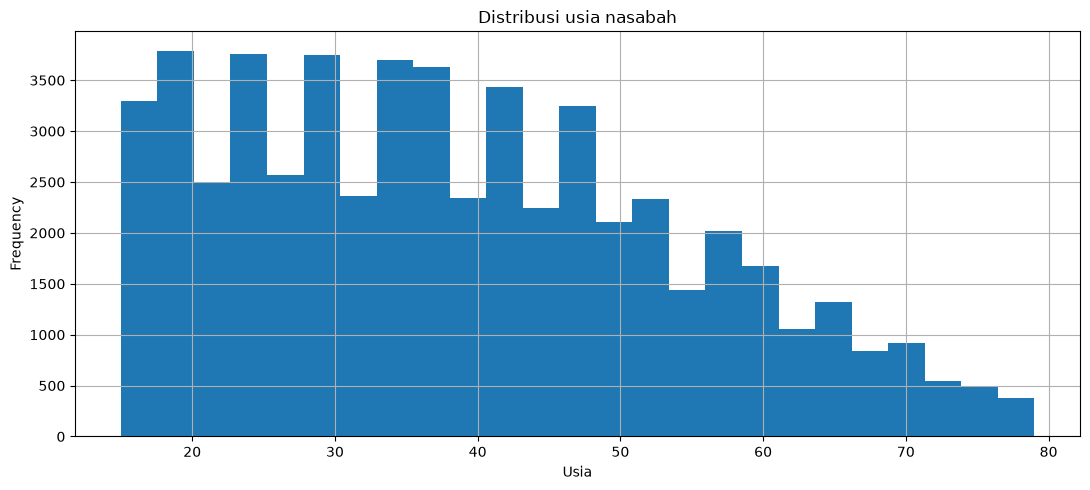

Baris panel bulanan: 886,639 | produk: 15


,penetrasi
tabungan_plus,0.7515
Mobile Banking,0.2636
tabungan_plus_muda,0.2353
Autodebit,0.1233
Bank Visa Platinum,0.1105
DPLK Pensiun,0.0687
Bank Payroll,0.0520
Bank Deposito,0.0361
Prioritas,0.0356
Bank Giro,0.0353


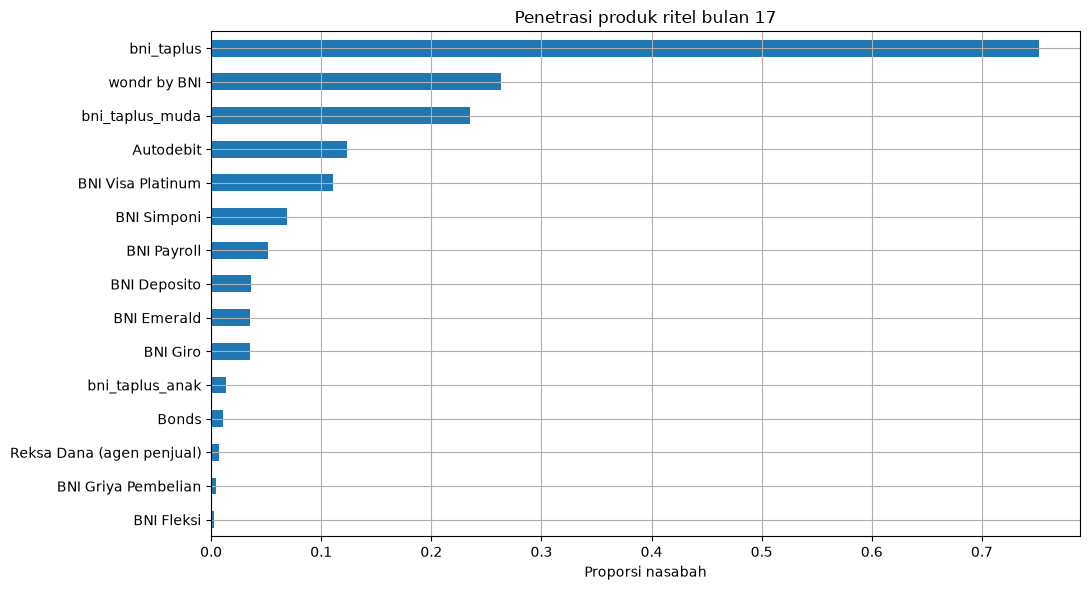

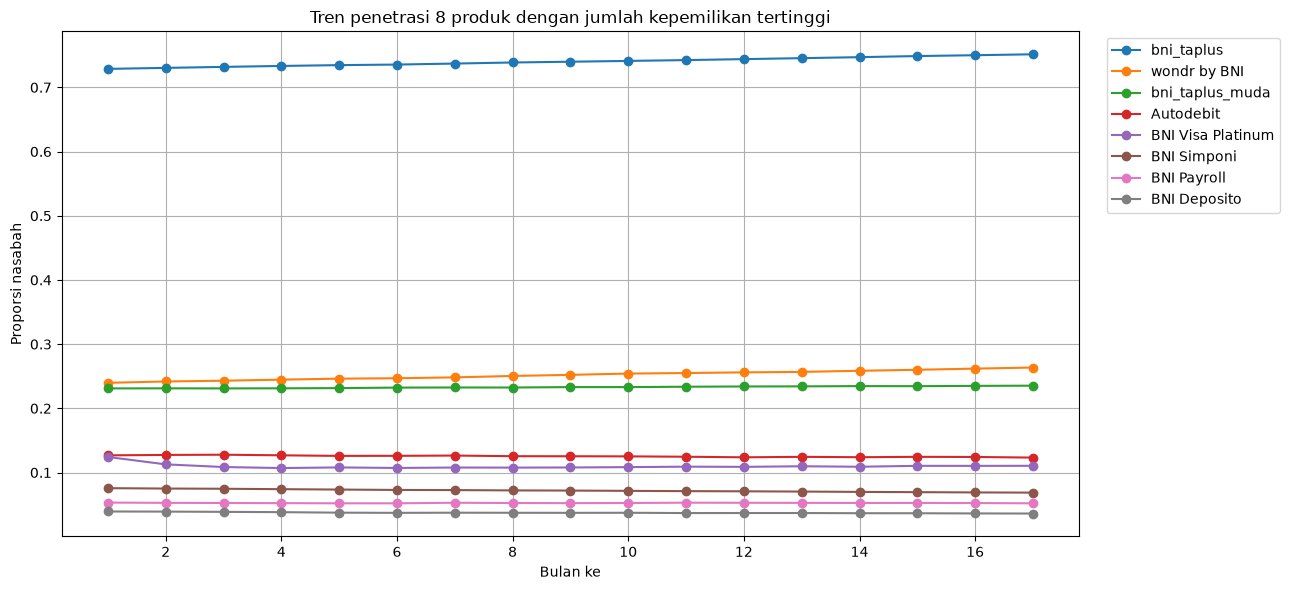

In [27]:
individuals = data.get("nasabah")
panel = data.get("nasabah_bulanan")
if individuals is not None:
    print("Nasabah perorangan:", f"{individuals['person_id'].nunique():,}" if "person_id" in individuals else f"{len(individuals):,}")
    display(individuals.head())
    for col in ["pekerjaan","kisaran_pendapatan","provinsi","channel","jenis_kelamin"]:
        if col in individuals:
            tab = individuals[col].fillna("Tidak diketahui").value_counts(dropna=False).head(12)
            display(tab.rename(f"Distribusi {col}").to_frame())
    if "usia_bulan1" in individuals:
        age = pd.to_numeric(individuals["usia_bulan1"], errors="coerce").dropna()
        print("Ringkasan usia:", age.describe(percentiles=[.25,.5,.75,.9]).round(2).to_dict())
        age.plot.hist(bins=25, title="Distribusi usia nasabah"); plt.xlabel("Usia"); plt.tight_layout(); plt.show()
else:
    print("Dataset nasabah tidak tersedia.")

if panel is not None:
    product_cols = [c for c in panel.columns if c.startswith("prod_")]
    print("Baris panel bulanan:", f"{len(panel):,}", "| produk:", len(product_cols))
    if product_cols and "bulan_ke" in panel:
        monthly_products = panel.groupby("bulan_ke")[product_cols].sum(min_count=1).sort_index()
        monthly_customers = panel.groupby("bulan_ke")["person_id"].nunique().sort_index() if "person_id" in panel else panel.groupby("bulan_ke").size()
        levels = data.get("produk_level", pd.DataFrame())
        product_names = dict(zip(levels["kolom"], levels["produk"])) if {"kolom","produk"}.issubset(levels.columns) else {}
        latest = monthly_products.index.max()
        denom = monthly_customers.reindex(monthly_products.index)
        penetration = monthly_products.div(denom, axis=0)
        latest_penetration = penetration.loc[latest].sort_values(ascending=False)
        latest_penetration.index = [product_names.get(c, c.removeprefix("prod_")) for c in latest_penetration.index]
        display(latest_penetration.rename("penetrasi").to_frame().round(4))
        latest_penetration.head(15).sort_values().plot.barh(figsize=(11,6), title=f"Penetrasi produk ritel bulan {latest}")
        plt.xlabel("Proporsi nasabah"); plt.tight_layout(); plt.show()

        top_cols = monthly_products.sum().sort_values(ascending=False).head(8).index
        trend = penetration[top_cols].copy()
        trend.columns = [product_names.get(c, c.removeprefix("prod_")) for c in trend.columns]
        trend.plot(marker="o", figsize=(13,6), title="Tren penetrasi 8 produk dengan jumlah kepemilikan tertinggi")
        plt.xlabel("Bulan ke"); plt.ylabel("Proporsi nasabah"); plt.legend(bbox_to_anchor=(1.02,1), loc="upper left")
        plt.tight_layout(); plt.show()


## 12. Sintesis insight dan hipotesis bisnis

Gunakan hasil tabel/grafik di atas untuk menyusun prioritas, bukan membuat keputusan otomatis. Pertanyaan yang dapat dibawa ke RM Copilot:

1. **Coverage pembiayaan:** sektor atau RM mana yang memiliki jumlah non-debitur tinggi, tetapi juga memiliki sinyal aktivitas bisnis dan saldo yang konsisten?
2. **Reaktivasi:** produk tidak aktif mana yang paling banyak muncul pada perusahaan dengan aktivitas transaksi terbaru?
3. **Cross-sell:** apakah perusahaan dengan saldo/arus transaksi tinggi belum memiliki produk wholesale yang relevan?
4. **Value chain acquisition:** anchor mana yang memiliki counterpart berulang lintas bulan, dan berapa bagian nominalnya yang mengalir ke bank lain?
5. **Kualitas rekomendasi:** apakah missingness, kelayakan produk, dan batas data bank-visible sudah menjadi guardrail fitur?
6. **Prioritisasi RM:** gabungkan ukuran peluang (nominal/volume), kekuatan sinyal (frekuensi dan kontinuitas), dan confidence data; jangan hanya mengurutkan berdasarkan nominal.


In [28]:
# Ringkasan otomatis sederhana; periksa output di atas sebelum menyusun kesimpulan final.
print("RINGKASAN EDA CLEAN")
print(f"- Dataset Parquet dimuat: {len(data)}")
print(f"- Perusahaan nasabah Commercial/Corporate: {corporate['company_id'].nunique():,}")
if len(segment_summary):
    print(f"- Segmen terbesar berdasarkan jumlah perusahaan: {segment_summary['perusahaan'].idxmax()}")
if sector_col:
    print(f"- Sektor terbanyak: {corporate[sector_col].value_counts().index[0]}")
if debt_col:
    print(f"- Proporsi debitur awal keseluruhan: {pd.to_numeric(corporate[debt_col], errors='coerce').mean():.1%}")
print("- Ingat: data sintetis; peluang yang teridentifikasi perlu validasi bisnis, eligibility, dan compliance.")


RINGKASAN EDA CLEAN
- Dataset Parquet dimuat: 15
- Perusahaan nasabah Commercial/Corporate: 1,233
- Segmen terbesar berdasarkan jumlah perusahaan: Commercial
- Sektor terbanyak: C
- Proporsi debitur awal keseluruhan: 67.6%
- Ingat: data sintetis; peluang yang teridentifikasi perlu validasi bisnis, eligibility, dan compliance.


## 13. Batasan interpretasi dan reproduksibilitas

- Dataset bersifat sintetis; pola yang terlihat tidak boleh diklaim sebagai pola aktual nasabah Bank.
- File `kunci_evaluasi`, truth, dan label target tidak digunakan sebagai prediktor.
- Missing tidak otomatis diimputasi ulang pada EDA. Perlakuan cleaning mengikuti pipeline; notebook ini hanya menganalisis hasilnya.
- Porsi transaksi ke bank lain dihitung berdasarkan klasifikasi kolom bank pada data clean; pastikan definisi `counterparty_bank` sesuai dengan kebutuhan bisnis.
- Perhitungan fasilitas/produk memakai perusahaan unik bila membahas cakupan, karena satu perusahaan dapat memiliki beberapa fasilitas atau riwayat.
- Jalankan semua sel dari atas ke bawah menggunakan environment project yang memiliki `pandas`, `pyarrow`, `numpy`, dan `matplotlib`.
